# Dallas 311 — Predicting Missed Service Deadlines

**Question:** When someone files a 311 request in Dallas, can we predict right away whether the city will miss its promised deadline?

**Data:** [Dallas OpenData 311 Service Requests](https://www.dallasopendata.com/resource/d7e7-envw) — closed requests created in 2025, excluding the 311 Customer Service Center department (400,717 rows).

This notebook covers data loading and preparation:
1. Load the 2025 data
2. Add `days_to_close`, `missed_deadline`, `latitude`, `longitude`
3. Data checks
4. Top 20 request types and their missed-deadline rates

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_PATH = "../data/dallas_311_2025.csv.gz"

## 1. Load the data

The compressed file was created by `src/download_data.py`, which pages through the Dallas OpenData API with these filters:
- `created_date` in 2025
- `status = 'Closed'`
- `department != '311 Customer Service Center'`

To re-download from scratch, run `python src/download_data.py` from the repo root.

In [2]:
df = pd.read_csv(DATA_PATH, dtype=str)
print(f"{len(df):,} rows, {df.shape[1]} columns")
df.head()

400,717 rows, 13 columns


,service_request_number,city_council_district,department,service_request_type,ert_estimated_response_time,overall_service_request_due_date,status,created_date,closed_date,outcome,priority,method_received_description,lat_location
0,24-00615137,7,Police Department,Fireworks - DPD,NaN,2025-01-07T00:59:00.000,Closed,2025-01-01T00:08:10.000,2025-01-01T00:08:10.000,NaN,Standard,Phone,"(32.75561138547856600,-96.65493570805230000)"
1,24-00615138,5,Police Department,Fireworks - DPD,NaN,2025-01-06T18:59:00.000,Closed,2025-01-01T00:10:22.000,2025-01-01T00:10:22.000,NaN,Standard,API,"(32.75727039931267000,-96.68858568750419000)"
2,24-00615139,5,Police Department,Fireworks - DPD,NaN,2025-01-06T18:59:00.000,Closed,2025-01-01T00:11:43.000,2025-01-01T00:11:43.000,NaN,Standard,API,"(32.77240252759392000,-96.69209356653950000)"
3,24-00615140,7,Police Department,Chronic Noise Complaint - DPD,3 Business Days,2025-01-11T00:59:00.000,Closed,2025-01-01T00:18:03.000,2025-01-08T08:29:46.000,Investigation Complete,Standard,API,"(32.81796851390457400,-96.67254718852263000)"
4,24-00615143,6,Dallas Animal Services,Animal Loose - DAS,1 Calendar Days,2025-01-04T00:59:00.000,Closed,2025-01-01T00:24:03.000,2025-01-01T01:24:27.000,Final Results,Dispatch,Phone,"(32.77255348959343000,-96.82270430898170000)"


## 2. Add new columns

In [3]:
for col in ["created_date", "closed_date", "overall_service_request_due_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Days from creation to closure
df["days_to_close"] = (df["closed_date"] - df["created_date"]).dt.total_seconds() / 86400

# 1 = closed after the due date; blank when there is no due date to compare against
has_both = df["overall_service_request_due_date"].notna() & df["closed_date"].notna()
df["missed_deadline"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
df.loc[has_both, "missed_deadline"] = (
    df.loc[has_both, "closed_date"] > df.loc[has_both, "overall_service_request_due_date"]
).astype(int)

# lat_location looks like "(32.838857,-96.670703)"
coords = df["lat_location"].str.strip("()").str.split(",", expand=True)
df["latitude"] = pd.to_numeric(coords[0], errors="coerce")
df["longitude"] = pd.to_numeric(coords[1], errors="coerce")

df[["service_request_type", "created_date", "closed_date", "overall_service_request_due_date",
    "days_to_close", "missed_deadline", "latitude", "longitude"]].head()

,service_request_type,created_date,closed_date,overall_service_request_due_date,days_to_close,missed_deadline,latitude,longitude
0,Fireworks - DPD,2025-01-01 00:08:10,2025-01-01 00:08:10,2025-01-07 00:59:00,0.000000,0,32.755611,-96.654936
1,Fireworks - DPD,2025-01-01 00:10:22,2025-01-01 00:10:22,2025-01-06 18:59:00,0.000000,0,32.757270,-96.688586
2,Fireworks - DPD,2025-01-01 00:11:43,2025-01-01 00:11:43,2025-01-06 18:59:00,0.000000,0,32.772403,-96.692094
3,Chronic Noise Complaint - DPD,2025-01-01 00:18:03,2025-01-08 08:29:46,2025-01-11 00:59:00,7.341470,0,32.817969,-96.672547
4,Animal Loose - DAS,2025-01-01 00:24:03,2025-01-01 01:24:27,2025-01-04 00:59:00,0.041944,0,32.772553,-96.822704


## 3. Data checks

In [4]:
print(f"days_to_close: median {df['days_to_close'].median():.2f} days, "
      f"negative values: {(df['days_to_close'] < 0).sum():,}")
print(f"missed_deadline: {df['missed_deadline'].sum():,} missed of "
      f"{df['missed_deadline'].notna().sum():,} with a due date "
      f"({df['missed_deadline'].mean():.1%})")
print(f"no due date: {df['missed_deadline'].isna().sum():,}")
print(f"latitude/longitude missing: {df['latitude'].isna().sum():,}")

days_to_close: median 2.22 days, negative values: 2
missed_deadline: 30,971 missed of 276,380 with a due date (11.2%)
no due date: 124,337
latitude/longitude missing: 62


Which request types have no due date?

In [5]:
df.loc[df["missed_deadline"].isna(), "service_request_type"].value_counts().head(10)

service_request_type
Code Concern - CCS                               124312
Community Prosecution - CAO                          19
Single Family Rental Needs Registration - CCS         2
TEST CRM                                              2
Neighborhood Code Tracking - CCS                      1
Traffic Signal - Other Dispatch - TPW                 1
Name: count, dtype: int64

**Finding:** almost every missing due date comes from **Code Concern – CCS**. Code compliance requests simply don't get a deadline, so this isn't random missing data. Code Concern stays in the exploratory charts but is left out of the prediction model.

## 4. Top 20 request types and missed-deadline rate

In [6]:
top = (
    df.groupby("service_request_type")
    .agg(
        requests=("service_request_number", "size"),
        with_due_date=("missed_deadline", "count"),
        missed=("missed_deadline", "sum"),
    )
    .sort_values("requests", ascending=False)
    .head(20)
)
top["missed_rate"] = top["missed"] / top["with_due_date"]
top.style.format({"requests": "{:,}", "with_due_date": "{:,}", "missed": "{:,}", "missed_rate": "{:.1%}"})

,requests,with_due_date,missed,missed_rate
service_request_type,,,,
Code Concern - CCS,"124,312",0,0,
Sanitation Roll Cart Maintenance/Delivery - SAN,"35,835","35,835","1,225",3.4%
Parking - Report a Violation - TPW,"35,658","35,658","2,606",7.3%
Animal Loose - DAS,"16,139","16,139","1,473",9.1%
Sanitation Missed Garbage - SAN,"13,047","13,047",794,6.1%
Animal Lack of Care - DAS,"12,977","12,977","3,818",29.4%
Animal Aggressive Behavior - DAS,"12,328","12,328","3,715",30.1%
Dead Animal Pick Up - DAS,"10,554","10,554",139,1.3%
Pot Hole - Routine - TPW,"5,230","5,230",681,13.0%


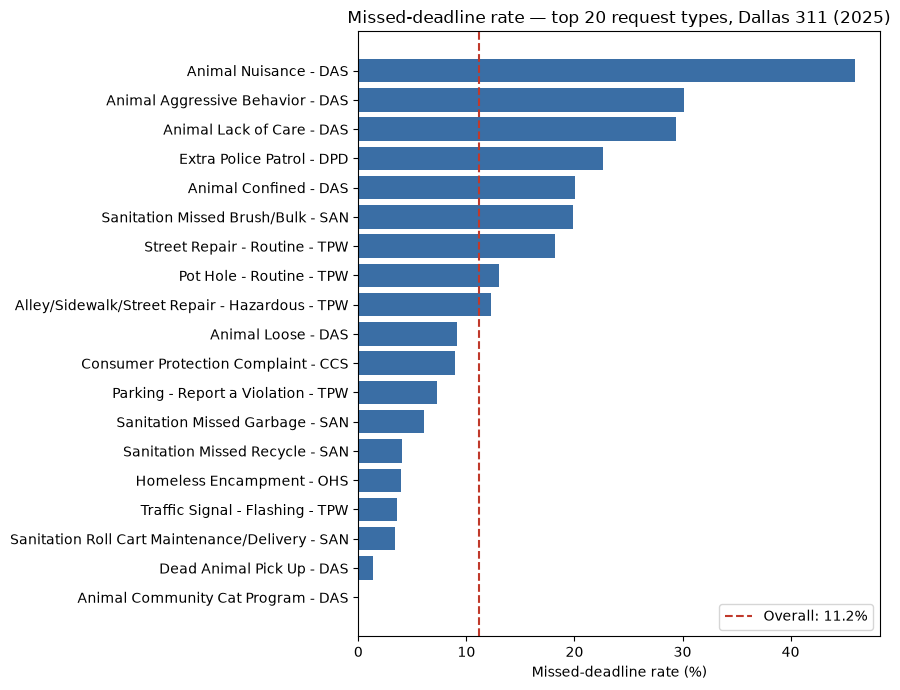

In [7]:
plot = top.dropna(subset=["missed_rate"]).sort_values("missed_rate")

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot.index, plot["missed_rate"] * 100, color="#3a6ea5")
ax.axvline(df["missed_deadline"].mean() * 100, color="#c0392b", linestyle="--",
           label=f"Overall: {df['missed_deadline'].mean():.1%}")
ax.set_xlabel("Missed-deadline rate (%)")
ax.set_title("Missed-deadline rate — top 20 request types, Dallas 311 (2025)")
ax.legend()
plt.tight_layout()
plt.show()

**Finding:** Animal Services stands out. Animal Nuisance (46%), Aggressive Behavior (30%) and Lack of Care (29%) miss far more often than other request types, while Dead Animal Pick Up in the same department misses only 1.3%.

## 5. Save the prepared data

In [8]:
df.to_csv("../data/dallas_311_enriched.csv", index=False)
print("Saved ../data/dallas_311_enriched.csv")

Saved ../data/dallas_311_enriched.csv
